# Example 5: test samples for the tensile tests

Circular patterns to check the ribbon theory with tensile tests. Each pattern has the same overlap $D$ and ribbon width $W$ on every level, an uncut rim to clamp and an uncut central pad to pull. The series change one parameter at a time around $N = 6$, $D = 3$ mm, $W = 4$ mm, so the measured stiffness can be checked against

$$k = \frac{E h^3 W N}{8 (1 - \nu^2) M D^3}$$

with $k \sim 1/D^3$, $k \sim N$ and $k \sim W/M$. Every sample fits the 220 × 220 mm bed of an xTool F1 Ultra.

Run the notebook from the `examples/` folder. The script `05_test_samples.py` does the same.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore", category = RuntimeWarning)   # fsolve progress warnings of the section lines
import os, importlib
import numpy as np
from common import *   # also puts ../lib on the path
example5 = importlib.import_module('05_test_samples')   # samples, pattern, sample_paths, write_svg, predictions

RADIUS = 70.0     # outer cut contour, mm
INNER = 14.0      # radius of the central pad, mm
RIM = 12.0        # width of the uncut rim, mm
HOLES = 8         # clamping holes in the rim (3.2 mm)
YOUNG, THICKNESS = 2100.0, 0.1
example5.SERIES   # the series, around example5.BASE

[('D', [2.0, 3.0, 4.0, 5.0]), ('N', [4, 6, 8]), ('W', [3.0, 4.0, 6.0])]

In [2]:
out = output_dir('05_test_samples')
diameter = 2*(RADIUS+RIM)
rows, drawn = [], []
for name, p in example5.samples(RADIUS, INNER).items():
    radii, lines, spans = example5.pattern(p)
    gap = example5.connector_gap(radii, p['N'], p['D'])
    if gap < p['W']/2:
        print('%s: skipped, the uncut connectors are only %.1f mm long' % (name, gap))
        continue
    paths = example5.sample_paths(p, lines, spans, RIM, HOLES)
    example5.write_svg(os.path.join(out, name+'.svg'), [((diameter/2+1, diameter/2+1), paths, '%s h%g' % (name, THICKNESS),
                       (0, -(p['R']+RIM/2)))], (diameter+2, diameter+2))
    r = example5.predictions(p, lines, spans, YOUNG, THICKNESS)
    rows.append((name, p['N'], p['D'], p['W'], r['M'], r['k'], r['k_formula']))
    drawn.append((name, paths))
    print('%-10s M = %2d levels, connectors %.1f mm, k = %.2e N/mm (closed form %.2e)' % (name, r['M'], gap, r['k'], r['k_formula']))

N6_D2_W4   M = 13 levels, connectors 14.8 mm, k = 7.15e-02 N/mm (closed form 7.21e-02)
N6_D3_W4   M = 13 levels, connectors 12.8 mm, k = 2.13e-02 N/mm (closed form 2.14e-02)
N6_D4_W4   M = 13 levels, connectors 10.8 mm, k = 8.98e-03 N/mm (closed form 9.01e-03)


N6_D5_W4   M = 13 levels, connectors 8.8 mm, k = 4.62e-03 N/mm (closed form 4.62e-03)
N4_D3_W4   M = 13 levels, connectors 22.3 mm, k = 1.42e-02 N/mm (closed form 1.42e-02)
N8_D3_W4   M = 13 levels, connectors 8.1 mm, k = 2.84e-02 N/mm (closed form 2.85e-02)


N6_D3_W3   M = 17 levels, connectors 13.9 mm, k = 1.23e-02 N/mm (closed form 1.23e-02)
N6_D3_W6   M =  8 levels, connectors 17.0 mm, k = 5.14e-02 N/mm (closed form 5.21e-02)


## The samples

Cuts are in red, and the outline and holes in blue. The SVG files are in `output/05_test_samples/`.

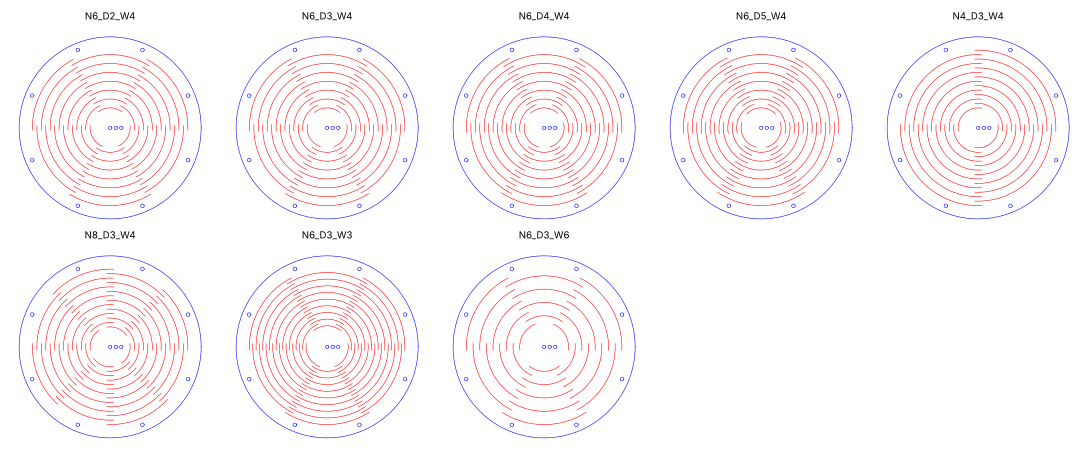

In [3]:
cols = 5
fig, axes = plt.subplots(int(np.ceil(len(drawn)/cols)), cols, figsize = (2.2*cols, 2.3*np.ceil(len(drawn)/cols)))
for ax in axes.ravel():
    ax.axis('off')
for ax, (name, paths) in zip(axes.ravel(), drawn):
    for c, q, closed in paths:
        q = np.vstack([q, q[:1]]) if closed else q
        ax.plot(q[:, 0], q[:, 1], '-', color = c, lw = 0.4)
    ax.set_aspect('equal')
    ax.set_title(name, fontsize = 7)
fig.tight_layout()
finish(fig, os.path.join(out, 'patterns.png'))

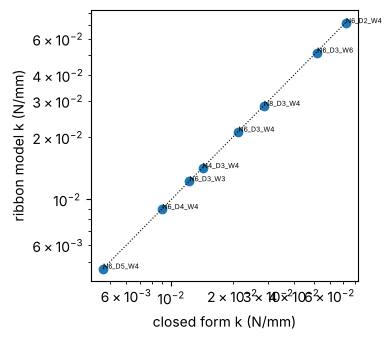

In [4]:
k = np.array([r[5] for r in rows]); kf = np.array([r[6] for r in rows])
fig, ax = plt.subplots(figsize = (4, 3.5))
ax.loglog(kf, k, 'o')
ax.loglog([kf.min(), kf.max()], [kf.min(), kf.max()], 'k:', lw = 0.8)
for r in rows:
    ax.annotate(r[0], (r[6], r[5]), fontsize = 5)
ax.set_xlabel('closed form k (N/mm)'); ax.set_ylabel('ribbon model k (N/mm)')
fig.tight_layout()
finish(fig, os.path.join(out, 'stiffness.png'))